# Knowledge Graph Statistics

This notebook analyzes the size and structure of the Knowledge Graphs (KGs) used in the experiments.
It calculates the number of unique entities, unique relations, and total edges for each distinct dataset.

In [1]:
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import numpy as np
from tqdm import tqdm

# Set plot style
plt.style.use('default')
sns.set_palette("deep")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
# Load configuration
project_root = Path("/Users/lukas/Workspace/Uni/BachelorsThesis/FICE")
config_path = project_root / "benchmarks" / "experiments_config.yaml"

with open(config_path, 'r') as f:
    config = yaml.safe_load(f)

# Extract unique graphs for datasets that have queries
queried_datasets = {q['dataset_name'] for q in config['queries']}
graphs = {}
for ds in config['datasets']:
    dataset_name = ds['name']
    if dataset_name in queried_datasets and dataset_name not in graphs:
        graphs[dataset_name] = str(project_root / ds['graph_path'])

print(f"Found {len(graphs)} unique datasets:")
for name, path in graphs.items():
    print(f"  - {name}: {path}")

Found 8 unique datasets:
  - lubm: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/lubm/raw/59410577
  - swdf: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/swdf/raw/59320634
  - wikidata: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/wikidata/raw/59320361
  - dbpedia100k: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/dbpedia100k/raw/59622674?private_link=f9b1fb2716ce2814515e
  - fb237_v4_ind: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/fb237_v4_ind/raw/59621825?private_link=364494eb331e3973ecb3
  - fb237_v4: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/fb237_v4/raw/59621618?private_link=a931a2f5f4c8c39cfb22
  - wn18rr_v4_ind: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/wn18rr_v4_ind/raw/59622656?private_link=49ad78ce6e253240223f
  - wn18rr_v4: /Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/wn18rr_v4/raw/59622641?private_link=e97f83a035f7e24bb37c


In [ ]:
def analyze_graph(name, path_str):
    """
    Reads a graph file (N-Triples format) and counts entities, relations, and edges.
    """
    path = Path(path_str)
    entities = set()
    relations = set()
    edge_count = 0
    
    print(f"Processing {name}...")
    try:
        with open(path, 'r') as f:
            for line in tqdm(f, desc=f"Reading {name}", unit=" lines"):
                line = line.strip()
                if not line:
                    continue
                
                # Split N-Triples: <s> <p> <o> .
                parts = line.split()
                if len(parts) >= 3:
                    s, p, o = parts[0], parts[1], parts[2]
                    
                    entities.add(s)
                    entities.add(o)
                    relations.add(p)
                    edge_count += 1
                    
    except Exception as e:
        print(f"Error processing {name}: {e}")
        return None

    return {
        'Dataset': name,
        'Entities': len(entities),
        'Relations': len(relations),
        'Edges': edge_count
    }

In [ ]:
# Run analysis
results = []

for name, path in graphs.items():
    stats = analyze_graph(name, path)
    if stats:
        results.append(stats)

df = pd.DataFrame(results)
df = df.sort_values('Edges', ascending=False)
print("\nAnalysis Complete!")
display(df)

Processing lubm...


Reading lubm: 2688849 lines [00:01, 2592624.12 lines/s]


Processing swdf...


Reading swdf: 242256 lines [00:00, 3650462.59 lines/s]


Processing wikidata...


Reading wikidata: 21354359 lines [00:11, 1787534.96 lines/s]


... (8 outputs left out)

Processing wn18rr_v4...


Reading wn18rr_v4: 9842 lines [00:00, 2673770.32 lines/s]


Analysis Complete!


,Dataset,Entities,Relations,Edges
2,wikidata,4818679,828,21354359
0,lubm,664048,18,2688849
3,dbpedia100k,99604,470,697572
1,swdf,76711,170,242256
5,fb237_v4,4707,219,33916
6,wn18rr_v4_ind,7084,9,15157
4,fb237_v4_ind,3051,200,14554
7,wn18rr_v4,3861,9,9842


## Visualizations

In [ ]:
# Helper function for plotting
def plot_metric(dataframe, metric, color, title, filename):
    plt.figure(figsize=(10, 6))
    ax = sns.barplot(x='Dataset', y=metric, data=dataframe, color=color)
    plt.yscale('log')
    
    # Add value labels on top of bars
    for p in ax.patches:
        value = p.get_height()
        if value > 0:
            ax.annotate(f'{int(value):,}', 
                        (p.get_x() + p.get_width() / 2., p.get_height()), 
                        ha = 'center', va = 'bottom', 
                        xytext = (0, 3), 
                        textcoords = 'offset points',
                        fontsize=10)
    
    plt.title(title, fontsize=16)
    plt.ylabel('Count (Log Scale)', fontsize=12)
    plt.xlabel('Dataset', fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7, which='both')
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

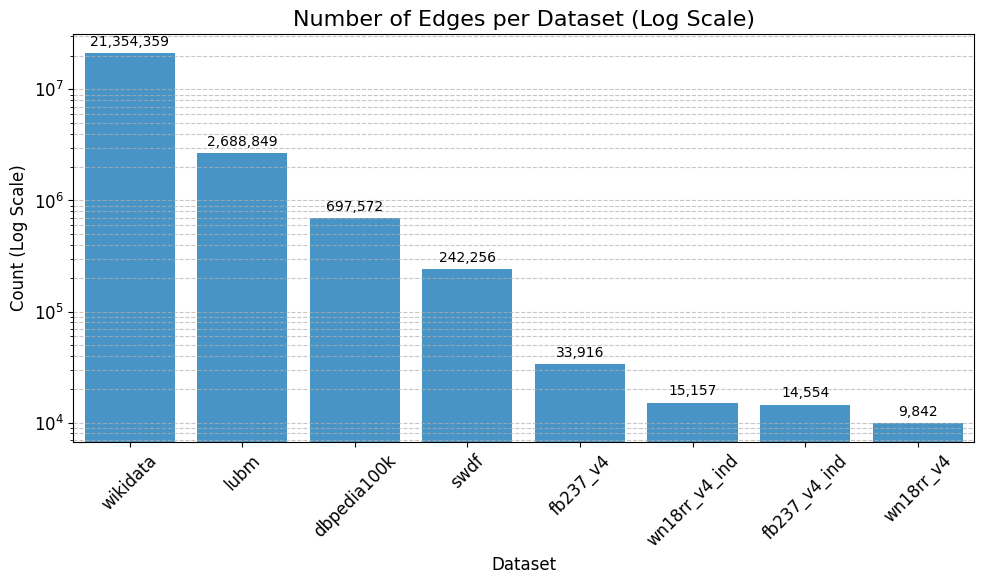

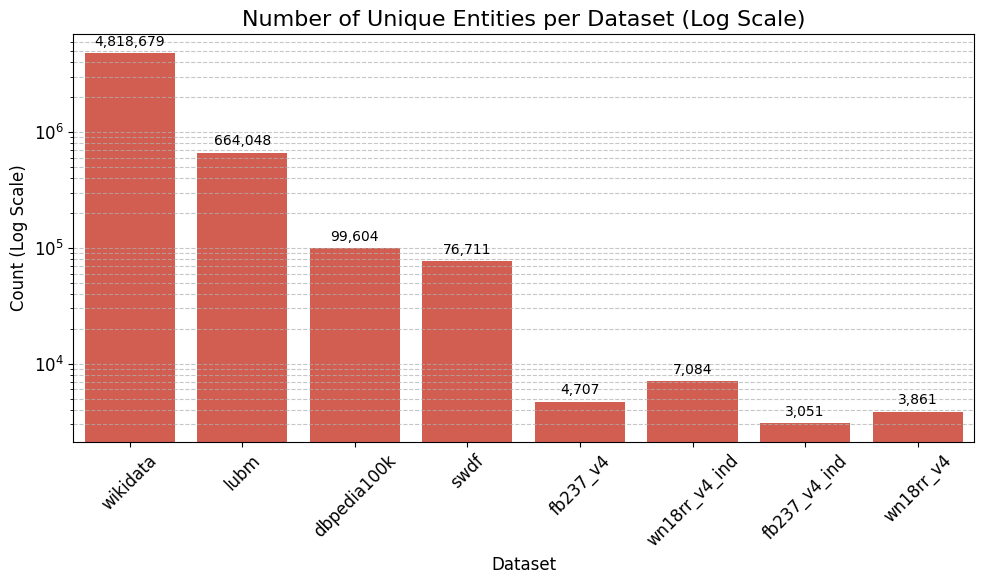

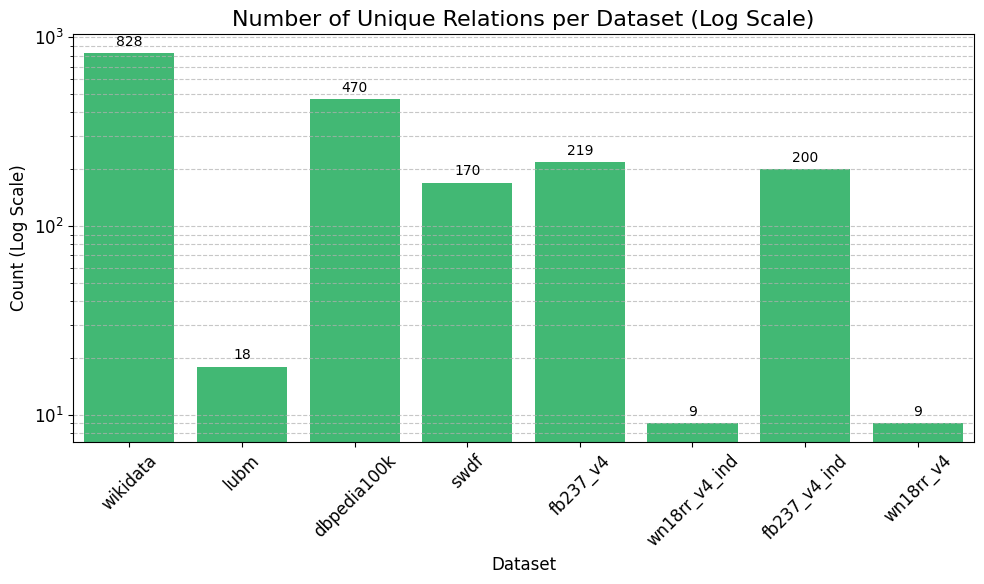

In [ ]:
# Plot Edges
plot_metric(df, 'Edges', '#3498db', 'Number of Edges per Dataset (Log Scale)', 'graph_edges.pdf')

# Plot Entities
plot_metric(df, 'Entities', '#e74c3c', 'Number of Unique Entities per Dataset (Log Scale)', 'graph_entities.pdf')

# Plot Relations
plot_metric(df, 'Relations', '#2ecc71', 'Number of Unique Relations per Dataset (Log Scale)', 'graph_relations.pdf')

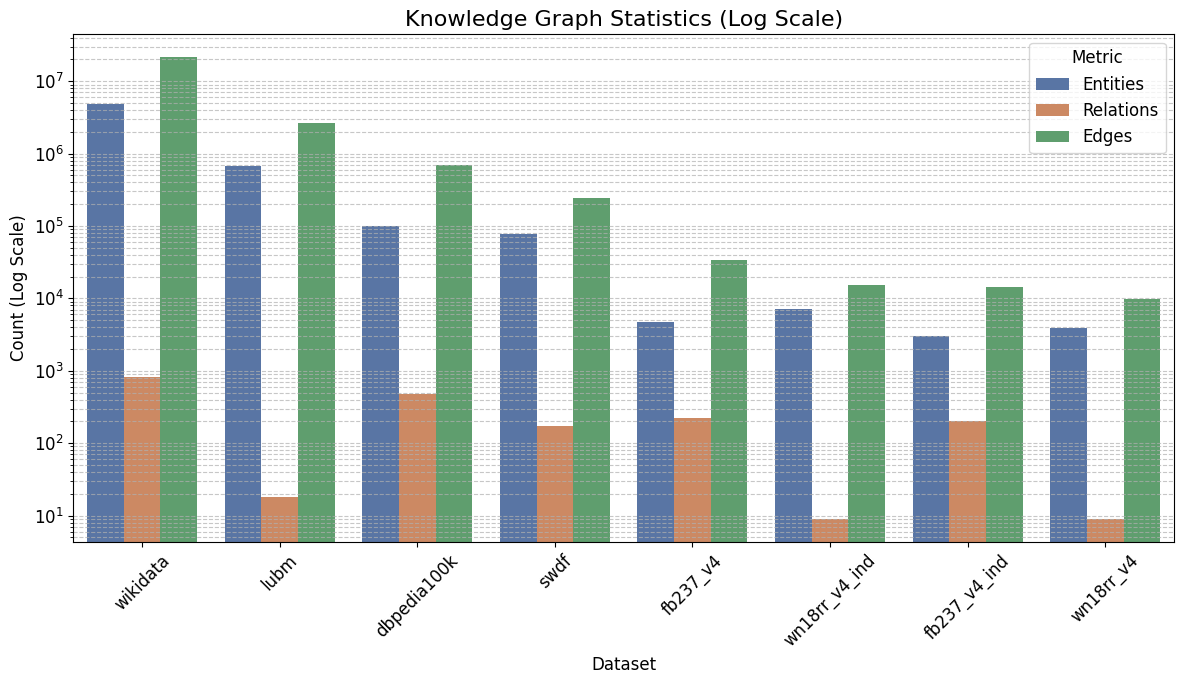

In [ ]:
# Combined log-scale plot for overview
df_melted = df.melt(id_vars='Dataset', var_name='Metric', value_name='Count')

plt.figure(figsize=(12, 7))
ax = sns.barplot(x='Dataset', y='Count', hue='Metric', data=df_melted)
plt.yscale('log')
plt.title('Knowledge Graph Statistics (Log Scale)', fontsize=16)
plt.ylabel('Count (Log Scale)', fontsize=12)
plt.xlabel('Dataset', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7, which='both')
plt.legend(title='Metric')
plt.tight_layout()
plt.savefig('graph_stats_combined_log.pdf', dpi=300)
plt.show()